In [1]:
from math import cos, radians
from datetime import datetime, timedelta

from eumetsearch import EUMDownloader, products_list
from eumetsearch.definitions import DATA_PATH

event_data = {
      "event_id": "EMSR760_2",
      "n_tiles": 339,
      "continent": "Europe",
      "country": "Portugal",
      "admin1": "Porto",
      "mgrs": "29TNF",
      "utm_zone": 29,
      "center_lat_deg": 41.1103,
      "center_lon_deg": -8.591,
      "acquisition_dates": [
        "2024-07-23",
        "2024-08-23",
        "2024-09-28",
        "2024-10-22"
      ]}

# Single 10-minute observation window at this UTC hour, on the first acquisition date
acquisition_hour = 12
start_time = datetime.strptime(event_data["acquisition_dates"][0], "%Y-%m-%d").replace(hour=acquisition_hour)
end_time = start_time + timedelta(minutes=10)

radius_km = 10
lat_delta = radius_km / 111.32
lon_delta = radius_km / (111.32 * cos(radians(event_data["center_lat_deg"])))

# EUMDownloader expects bounding boxes as [N, S, W, E]
NSWE = [
    event_data["center_lat_deg"] + lat_delta,  # North
    event_data["center_lat_deg"] - lat_delta,  # South
    event_data["center_lon_deg"] - lon_delta,  # West
    event_data["center_lon_deg"] + lon_delta,  # East
]

product_id = products_list["MSG-SEVIRI-L1-HRY"]["product_id"]

downloader = EUMDownloader(
    product_id=product_id,
    output_dir=str(DATA_PATH / "datastore_data"),
)

file_list = downloader.download_single(
    start_time=start_time.strftime("%Y-%m-%dT%H:%M:%S"),
    end_time=end_time.strftime("%Y-%m-%dT%H:%M:%S"),
    bounding_box=NSWE,
    method="datatailor",
)


/shared/home/rdercole/Riccardo/projects/eumetsearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Trying again for GET https://api.eumetsat.int:443/epcs/customisations/3e56dc2d due to server response 502 - "b'<html><body><h1>502 Bad Gateway</h1>\nThe server returned an invalid or incomplete response.\n</body></html>\n\n'" 
Trying again for GET https://api.eumetsat.int:443/epcs/customisations/3e56dc2d due to server response 503 - "b'<html><body><h1>503 Service Unavailable</h1>\nNo server is available to handle this request.\n</body></html>\n\n'" 


In [2]:
%matplotlib inline
import sys
import numpy as np
import zarr
import matplotlib.pyplot as plt
from pathlib import Path

sys.path.insert(0, str(Path("..").resolve()))
from definitions import DATA_PATH
from eumetsearch.transform import fci_ndvi_one_timestamp, grid_id_to_latlon

path = "datastore_data/mtg_june_2025_majortom.zarr"
ds = zarr.open(DATA_PATH / path, mode="r")
print("timestamps:", sorted(ds["patches"]["vis_06"].keys()))


/home/riccardo/Desktop/projects/eumetsearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


timestamps: ['2025-06-01T09:00:00', '2025-06-01T10:00:00', '2025-06-01T11:00:00', '2025-06-01T12:00:00', '2025-06-01T13:00:00', '2025-06-02T09:00:00', '2025-06-02T10:00:00', '2025-06-02T11:00:00', '2025-06-02T12:00:00', '2025-06-02T13:00:00', '2025-06-03T09:00:00', '2025-06-03T10:00:00']


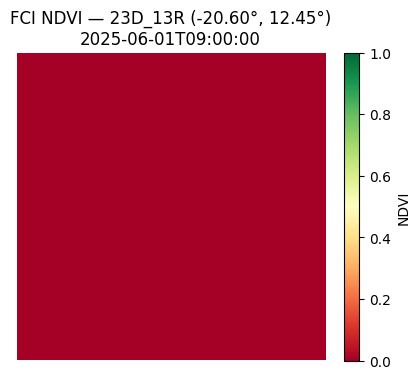

In [4]:
# NDVI for one timestamp — pick the first available
ts = sorted(ds["patches"]["vis_06"].keys())[0]
patch_ndvi = fci_ndvi_one_timestamp(ds, ts)

# Plot patch index 5000 (or wrap if fewer patches exist)
sample_gid = sorted(patch_ndvi.keys())[5000 % len(patch_ndvi)]
ndvi = patch_ndvi[sample_gid]
lat, lon = grid_id_to_latlon(sample_gid)

plt.figure(figsize=(5, 4))
plt.imshow(ndvi, cmap="RdYlGn", vmin=0, vmax=1)
plt.colorbar(label="NDVI")
plt.title(f"FCI NDVI — {sample_gid} ({lat:.2f}°, {lon:.2f}°)\n{ts}")
plt.axis("off")
plt.show()


## FCI + MODIS NDVI comparison

**Goal**: compute per-observation NDVI from FCI and from MODIS MOD09GA, aggregate to daily max, and compare values on matching MajorTOM grid cells.

- **FCI NDVI**: `(vis_08 - vis_06) / (vis_08 + vis_06)` (NIR=vis_08 865 nm, Red=vis_06 600 nm)
- **MODIS NDVI**: `(sur_refl_b02 - sur_refl_b01) / (sur_refl_b02 + sur_refl_b01)` (NIR=b02 841–876 nm, Red=b01 620–670 nm)

Grid cells are identified by MajorTOM `grid_id` strings (e.g. `23D_51L`) — same convention in both datasets, so cells with the same ID are the same ~100 km patch on Earth.

In [3]:
%matplotlib inline
import sys
import numpy as np
import zarr
import matplotlib.pyplot as plt
from pathlib import Path

sys.path.insert(0, str(Path("..").resolve()))
from definitions import DATA_PATH
from eumetsearch.transform import grid_id_to_latlon, grid_ids_to_latlons
from eumetsearch.transform import fci_ndvi_daily_max, modis_ndvi_one_date
from eumetsearch.viz import plot_ndvi_map, compare_ndvi_scatter, compare_tiles

FCI_ZARR   = Path(DATA_PATH) / "datastore_data" / "mtg_june_2025_majortom.zarr"
MODIS_ZARR = Path("/home/riccardo/Desktop/projects/modis-majortom/data/modis/MOD09GQ_dataset.zarr")

fci   = zarr.open(str(FCI_ZARR),   mode="r")
modis = zarr.open(str(MODIS_ZARR), mode="r")

print("FCI   timestamps:", sorted(fci["patches"]["vis_06"].keys()))
print("MODIS dates:     ", sorted(modis["patches"]["sur_refl_b01"].keys())[:6], "…")


FCI   timestamps: ['2025-06-01T09:00:00', '2025-06-01T10:00:00', '2025-06-01T11:00:00', '2025-06-01T12:00:00', '2025-06-01T13:00:00', '2025-06-02T09:00:00', '2025-06-02T10:00:00', '2025-06-02T11:00:00', '2025-06-02T12:00:00', '2025-06-02T13:00:00', '2025-06-03T09:00:00', '2025-06-03T10:00:00']
MODIS dates:      ['2025-06-01', '2025-06-02'] …


In [ ]:
day = "2025-06-02"

fci_daily  = fci_ndvi_daily_max(fci, day)
modis_ndvi = modis_ndvi_one_date(modis, day)

vals   = [v for v in fci_daily.values() if np.isfinite(v)]
vals_m = list(modis_ndvi.values())
print(f"FCI  daily-max NDVI: {len(fci_daily)} cells — range: {min(vals):.3f} – {max(vals):.3f}  (median {np.median(vals):.3f})")
print(f"MODIS NDVI:          {len(modis_ndvi)} cells — range: {min(vals_m):.3f} – {max(vals_m):.3f}  (median {np.median(vals_m):.3f})")


In [ ]:
# --- Geographic overlap between the two datasets ---
fci_gids   = set(fci_daily.keys())
modis_gids = set(modis_ndvi.keys())
overlap    = sorted(fci_gids & modis_gids)

print(f"FCI cells  : {len(fci_gids)}")
print(f"MODIS cells: {len(modis_gids)}")
print(f"Overlap    : {len(overlap)} grid cells")

if overlap:
    print("Sample overlapping IDs:", overlap[:5])
else:
    # Show the bounding boxes to understand why there's no overlap
    fci_lats, fci_lons = grid_ids_to_latlons(sorted(fci_gids))
    mod_lats, mod_lons = grid_ids_to_latlons(sorted(modis_gids))
    print("\n  FCI  coverage  — lat: [{:.1f}, {:.1f}]  lon: [{:.1f}, {:.1f}]".format(
        fci_lats.min(), fci_lats.max(), fci_lons.min(), fci_lons.max()))
    print("  MODIS coverage — lat: [{:.1f}, {:.1f}]  lon: [{:.1f}, {:.1f}]".format(
        mod_lats.min(), mod_lats.max(), mod_lons.min(), mod_lons.max()))
    print("\n  No overlap: the MODIS zarr covers South America; the FCI zarr covers Europe/Africa.")
    print("  Re-run the FCI pipeline over South America (lon_min=-80, lat_min=-40,")
    print("  lon_max=-30, lat_max=15) to get matching tiles.")

FCI cells  : 21225
MODIS cells: 19958
Overlap    : 10392 grid cells
Sample overlapping IDs: ['10D_10R', '10D_12L', '10D_12R', '10D_13L', '10D_13R']


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
plot_ndvi_map(fci_daily,  "FCI daily-max NDVI  (2025-06-02, Europe/Africa)",  ax=axes[0])
plot_ndvi_map(modis_ndvi, "MODIS MOD09GQ NDVI  (2025-06-01, South America)", ax=axes[1])
plt.tight_layout()
plt.show()


In [ ]:
compare_ndvi_scatter(fci_daily, modis_ndvi)


### To get geographic overlap

Run the FCI pipeline over South America (the region covered by the MODIS zarr):

```bash
cd /home/riccardo/Desktop/projects/eumetsearch
uv run python -m eumetsearch.data_collection.pipeline_data \
    --product MTG-FCI-L1C-FDHSI \
    --channels vis_06 vis_08 \
    --lon_min -80 --lat_min -40 --lon_max -30 --lat_max 15 \
    --n_lat 1 --n_lon 1 \
    --start_date 2025-06-01T09:00:00 \
    --end_date   2025-06-01T13:00:00 \
    --observations_per_day 5 --jump_minutes 60 \
    --majortom --dtype float16 --min_land_fraction 30 \
    --delete_temp --yes \
    --consolidated_label mtg_southamerica_june2025
```

Then re-open the new zarr and call `compare_ndvi_scatter(fci_daily_sa, modis_ndvi)` — the ~200 MODIS cells should appear in both datasets.

## Tile-by-tile visual comparison

For each overlapping MajorTOM cell show the raw bands and NDVI from both sensors side-by-side:

| FCI vis_06 (Red) | FCI vis_08 (NIR) | FCI NDVI | MODIS b01 (Red) | MODIS b02 (NIR) | MODIS NDVI |

Ranking 5655 overlapping cells by |FCI − MODIS| NDVI…


/tmp/ipykernel_2773076/3558830788.py:60: RuntimeWarning: All-NaN slice encountered
  mod_sc[g] = float(np.nanmedian(ndvi))
/tmp/ipykernel_2773076/3558830788.py:60: RuntimeWarning: All-NaN slice encountered
  mod_sc[g] = float(np.nanmedian(ndvi))


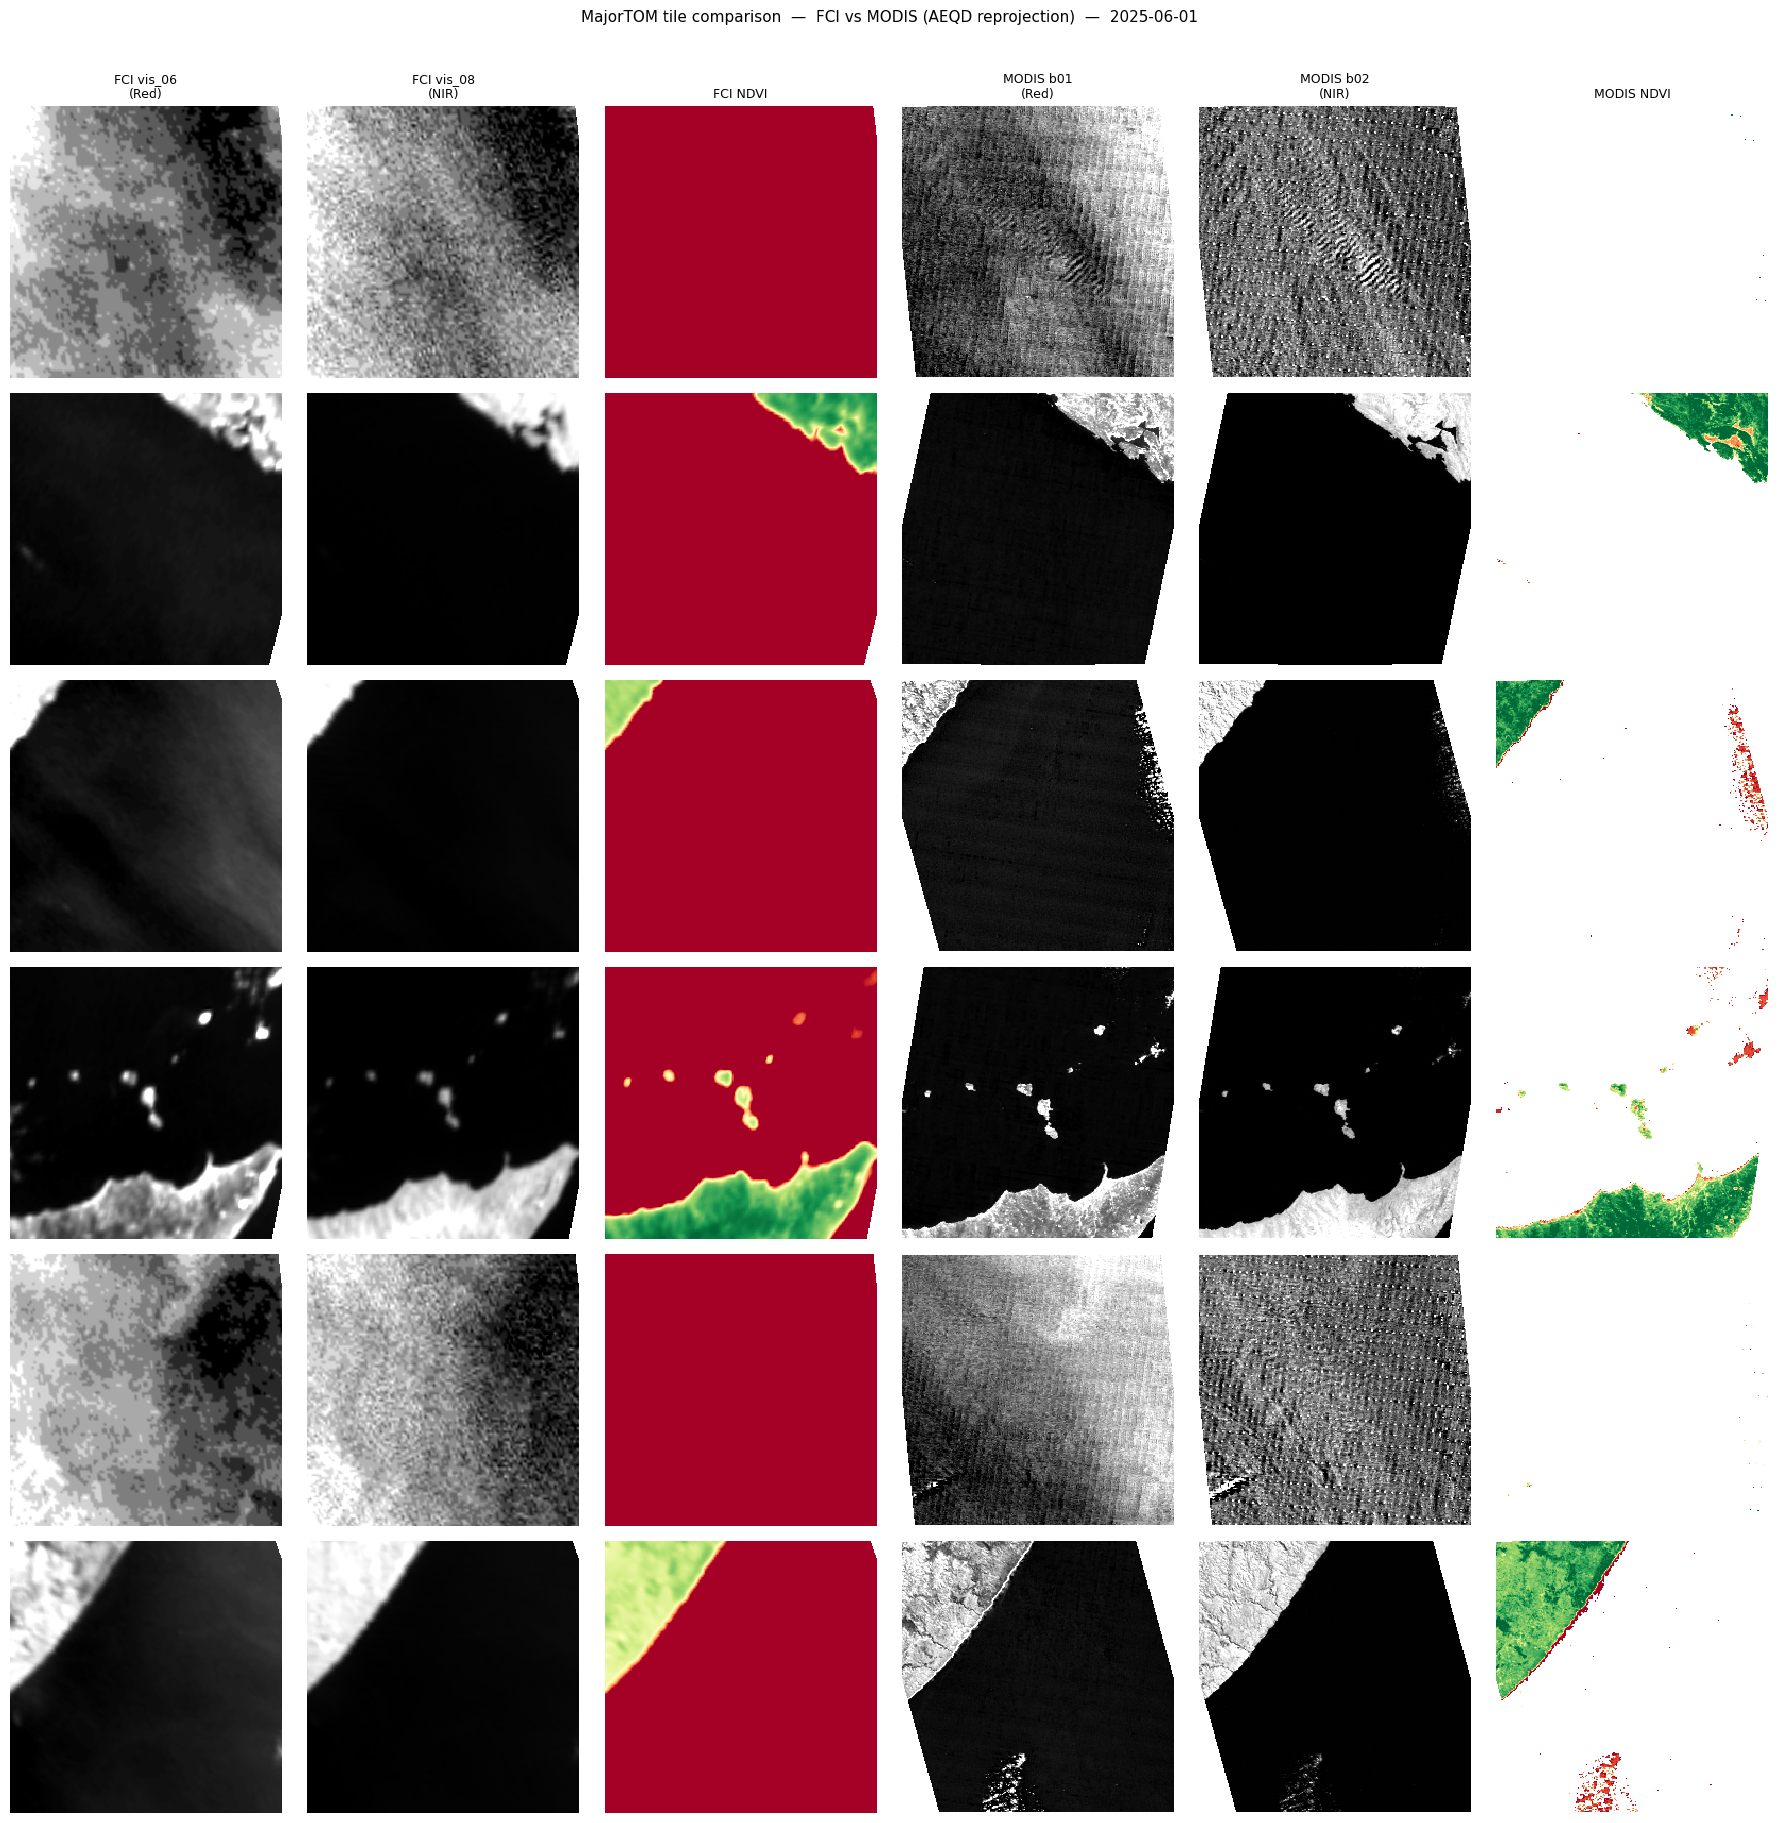

Showed 6 tiles  (5655 overlapping cells available)


: 

In [ ]:
# --- Show 6 tiles sorted by largest FCI vs MODIS NDVI difference ---
compare_tiles(fci, modis, date="2025-06-01", n=6, sort_by="ndvi_diff")

Loading MODIS for 5655 cells (parallel)…


/tmp/ipykernel_2773076/3558830788.py:48: RuntimeWarning: All-NaN slice encountered
  mod_sc[g] = float(np.nanmedian(ndvi))
/tmp/ipykernel_2773076/3558830788.py:48: RuntimeWarning: All-NaN slice encountered
  mod_sc[g] = float(np.nanmedian(ndvi))


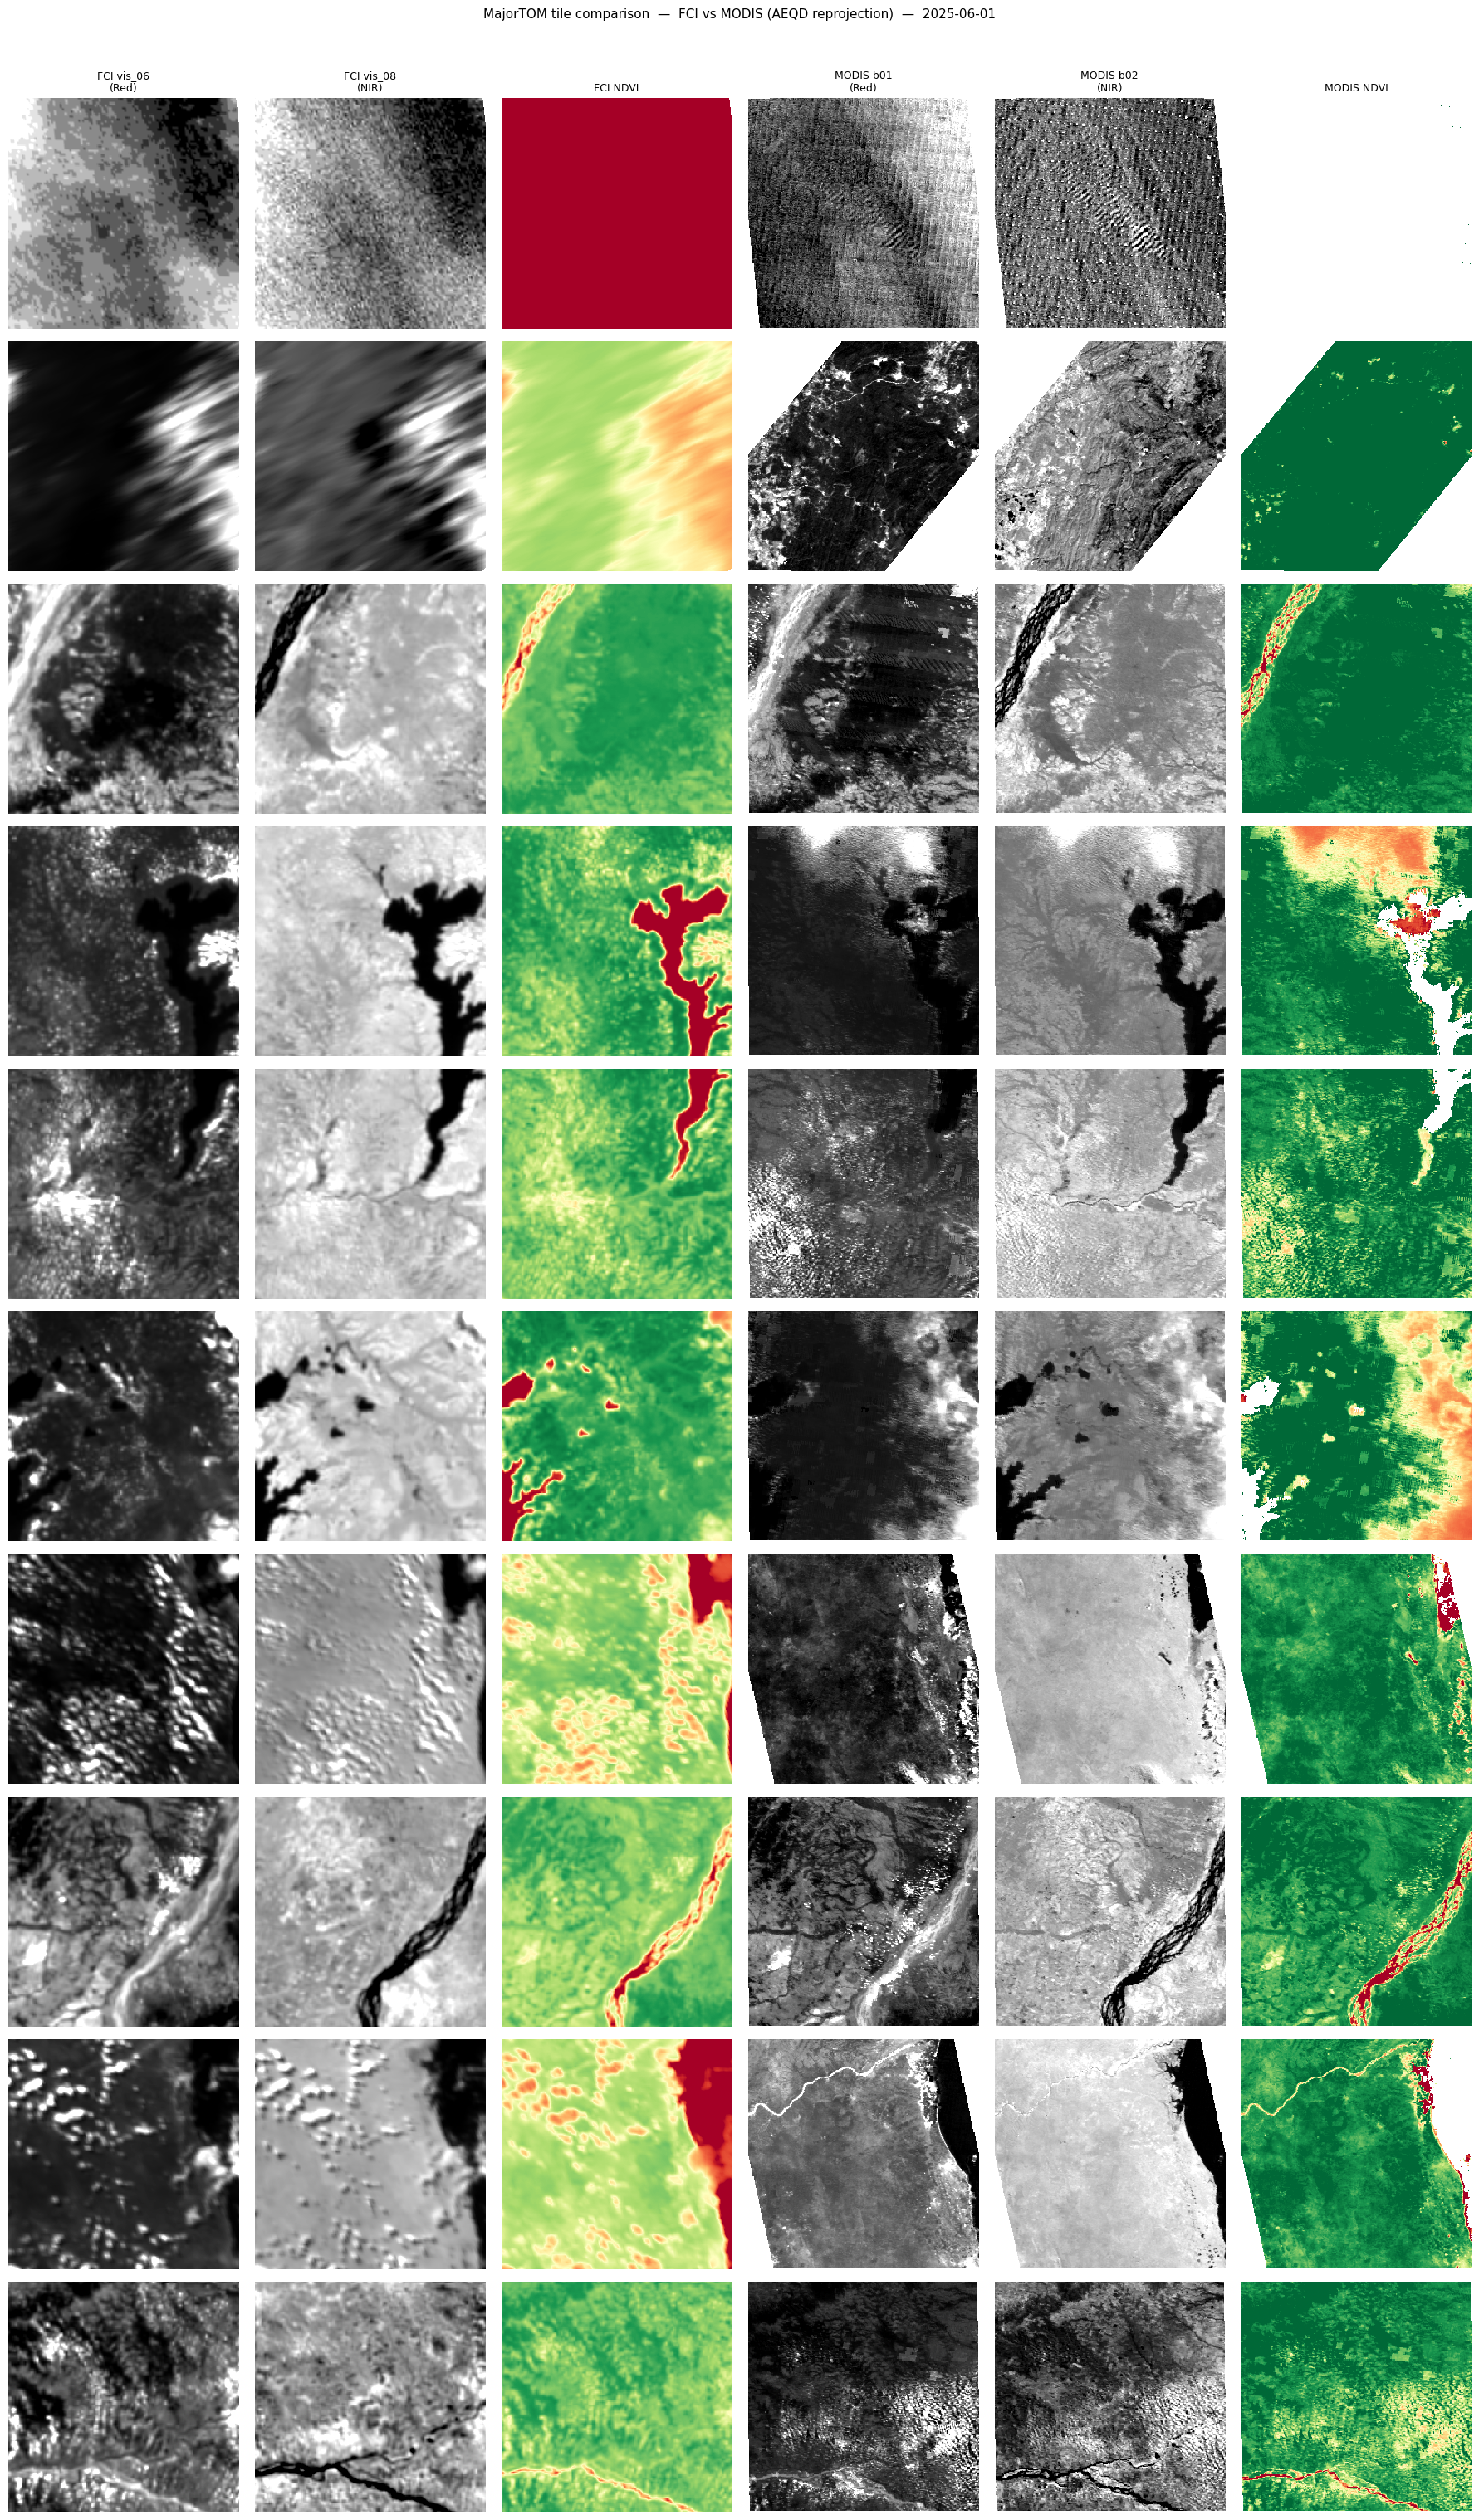

Showed 10 tiles  (5655 overlapping cells available)


In [11]:
# --- Greenest tiles (highest MODIS NDVI) ---
compare_tiles(fci, modis, date="2025-06-01", n=10, sort_by="ndvi")

# --- Or browse a random sample ---
# compare_tiles(fci, modis, date="2025-06-01", n=8, sort_by="random")

# --- Or inspect specific grid cells by ID ---
# compare_tiles(fci, modis, date="2025-06-01", gid_list=["12D_10L", "15U_22R", "20D_5L"])